Download complete.


/usr/local/lib/python3.13/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
W1001 02:56:07.796000 1659 torch/fx/_symbolic_trace.py:53] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Please use is_fx_tracing_symbolic_tracing() for specifically fx.symbolic_trace or torch.compiler.is_compiling() for specifically torch.export/compile.


Inference completed successfully!


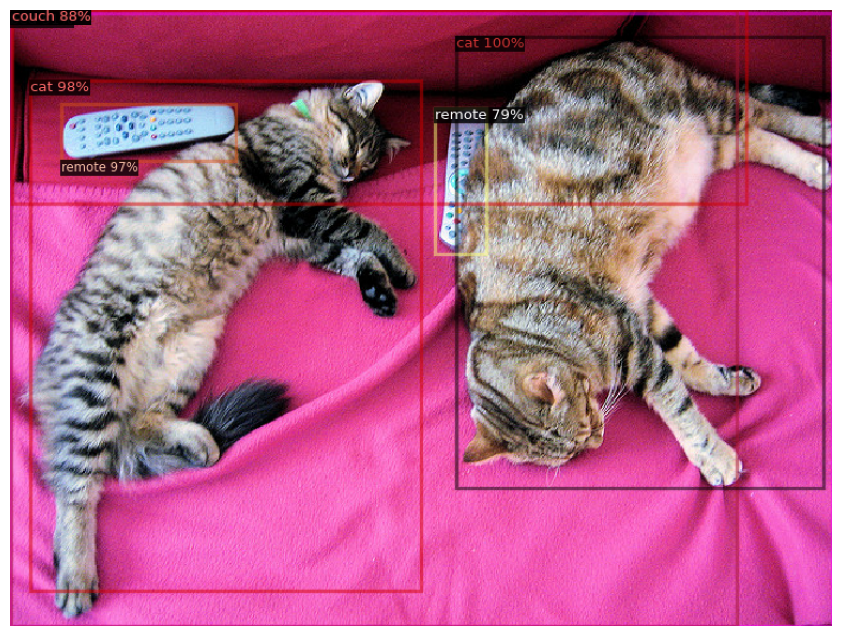

In [ ]:
!pip install git+https://github.com/facebookresearch/detectron2.git
import os
import cv2
import torch
import requests
import matplotlib.pyplot as plt

from detectron2.config import get_cfg
from detectron2 import model_zoo
from detectron2.engine import DefaultPredictor
from detectron2.utils.visualizer import Visualizer
from detectron2.data import MetadataCatalog

cfg = get_cfg()
cfg.merge_from_file(
    model_zoo.get_config_file("COCO-Detection/faster_rcnn_R_50_FPN_3x.yaml")
)

cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(
    "COCO-Detection/faster_rcnn_R_50_FPN_3x.yaml"
)
cfg.MODEL.DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

predictor = DefaultPredictor(cfg)

image_path = "sample_image.jpg"
image_url = "http://images.cocodataset.org/val2017/000000039769.jpg"

if not os.path.exists(image_path):
    print("Downloading sample image...")
    res = requests.get(image_url, headers={'User-Agent': 'Detectron2Lab/1.0'})
    if res.status_code == 200:
        with open(image_path, "wb") as f:
            f.write(res.content)
        print("Download complete.")
    else:
        raise RuntimeError(f"Failed to download image. HTTP status: {res.status_code}")

image = cv2.imread(image_path)

if image is None:
    raise FileNotFoundError(f"Could not read '{image_path}'. Ensure the file exists and is valid.")

outputs = predictor(image)
print("Inference completed successfully!")

v = Visualizer(
    image[:, :, ::-1],
    metadata=MetadataCatalog.get(cfg.DATASETS.TRAIN[0]),
    scale=1.2
)
out = v.draw_instance_predictions(outputs["instances"].to("cpu"))

res_img = out.get_image()
cv2.imwrite("detection_result.jpg", cv2.cvtColor(res_img, cv2.COLOR_RGB2BGR))

plt.figure(figsize=(12, 8))
plt.imshow(res_img)
plt.axis("off")
plt.show()